RFY6D#                                                                                                 FRHHHHH Introduction

This Walmart Sales Forecasting project analyzes historical sales data from different stores and departments to predict future demand. It examines weekly sales, holidays, seasonal patterns, and other factors using data analysis and machine learning techniques. The forecasts can help improve inventory planning, staffing, operational efficiency, decision-making, and customer satisfaction overall.


## Problem Statement

A retail store that has multiple outlets across the country are facing issues in managing the
inventory - to match the demand with respect to supply.


## Dataset Information

1. **Store** – Contains the store number.
2. **Date** – A section contains 'week of sales'
3. **Weekly_Sales** – Sales for the given store in that week
4. **Holiday_Flag** – If it is a holiday week
5. **Temperature** - Temperature on the day of the sale
6. **Fuel_Price** - Cost of the fuel in the region
7. **CPI** - Consumer Price Index
8. **Unemployment** - Unemployment Rate

## Steps We will take

In this notebook, we will follow a structured approach to wrangle the movie datasets. The steps include:

1. **Data Gathering**: Import necessary libraries (pandas, numpy) and load the datasets.
2. **Data Assessing & Cleaning**: Manually export for review and programmatically check structure, missing values, duplicates, and statistics.
3. **Validation**: Re-check the cleaned data.
4. **Exploratory Data Analysis**: Finding the hidden patter inside data distribution.
5. **Model fitting**: fit the data on the best suited model.
6. **Model Evaluation & validation**: check the model accuracy and performance on varius metric
7. **Model Deployement**: Simple flask app to check the model performance

### Data Gathering:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

In [3]:
df = pd.read_csv('Walmart.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


### Data Assessing & Cleaning:

- Over Here we are going to perform two type of Data assessing.
1. Mannual Assessing (using Excel)
2. Programatic Assessing (using Pandas or numpy)

- Afterwards we will write all the issues, in order to clean our data.


In [5]:
df['Date']  = pd.to_datetime(df['Date'], dayfirst= True)

In [6]:
df.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

#### Observation with the dataset found

**Data - `Walmart.csv`**

- Date Column found in diffrent format
- No null value found in any column








### Validation

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 402.3 KB


#### Note:
- Feaure has been converted in right format.

### Exploratory Data Analysis

**a. If the weekly sales are affected by the unemployment rate, if yes - which stores
are suffering the most?**

In [8]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [24]:
df['Weekly_Sales(mn)'] = df['Weekly_Sales']/1000000

In [32]:
df_sales_unemp = df.groupby('Date', as_index=False).agg(
    weekly_sales=('Weekly_Sales(mn)', 'sum'),
    unemployment=('Unemployment', 'mean')
).rename(columns={'Store': 'store_id'})

In [33]:
df_sales_unemp

,Date,weekly_sales,unemployment
0,2010-02-05,49.750740,8.619311
1,2010-02-12,48.336678,8.619311
2,2010-02-19,48.276994,8.619311
3,2010-02-26,43.968571,8.619311
4,2010-03-05,46.871470,8.619311
...,...,...,...
138,2012-09-28,43.734899,7.237333
139,2012-10-05,47.566639,6.953711
140,2012-10-12,46.128514,6.953711
141,2012-10-19,45.122411,6.953711


In [34]:
df_sales_unemp['unemployment'].corr(df_sales_unemp['weekly_sales'])

np.float64(0.0035235631054965073)

In [35]:
correlation_list = []

for store_id, data in df.groupby('Store'):

    corr = data['Weekly_Sales(mn)'].corr(data['Unemployment'])

    correlation_list.append({
        'store_id': store_id,
        'correlation': corr
    })

corr_df = pd.DataFrame(correlation_list)


In [36]:
corr_df.sort_values(by ='correlation', ascending= True).head(10)

,store_id,correlation
37,38,-0.785290
43,44,-0.780076
38,39,-0.384681
41,42,-0.356355
40,41,-0.350630
3,4,-0.337015
16,17,-0.263600
2,3,-0.230413
36,37,-0.221287
4,5,-0.207043


#### Observation






- There is a weak positive coorelation between 'Unemployment' & 'Weekly_Sales(mn)'. 
- Store no. 38 and 44 has marked as highly affected


**b. If the weekly sales show a seasonal trend, when and what could be the reason?**

In [37]:
new_df = df.groupby('Date', as_index=False).agg({
    'Weekly_Sales(mn)': 'sum',
    'Holiday_Flag': 'mean'
})

In [38]:
new_df['Holiday_Flag'] = new_df['Holiday_Flag'].replace(0.0, " ")

In [39]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=new_df["Date"],
        y=new_df["Weekly_Sales(mn)"],
        mode="lines",
        name="Total Sales"
    )
)

fig.add_trace(
    go.Scatter(
        x=new_df["Date"],
        y= new_df["Holiday_Flag"],
        mode="markers",
        name="Holiday Flag",
        yaxis="y2"
    )
)

fig.update_layout(
    title="Total Sales and Holiday Flag Over Time",
    xaxis_title="Date",
    yaxis_title="Total Sales (Millions)",
    yaxis2={
        "title": "Holiday Flag",
        "overlaying": "y",
        "side": "right",
        "tickmode": "linear",
        "dtick": 1
    },
    hovermode="x unified"
)

fig.show()

#### Observation:

- 31st Dec &  26th Nov holiday has high sales spike.


**c. Does temperature affect the weekly sales in any manner?**


Correlation between temperature and weekly sales: -0.064


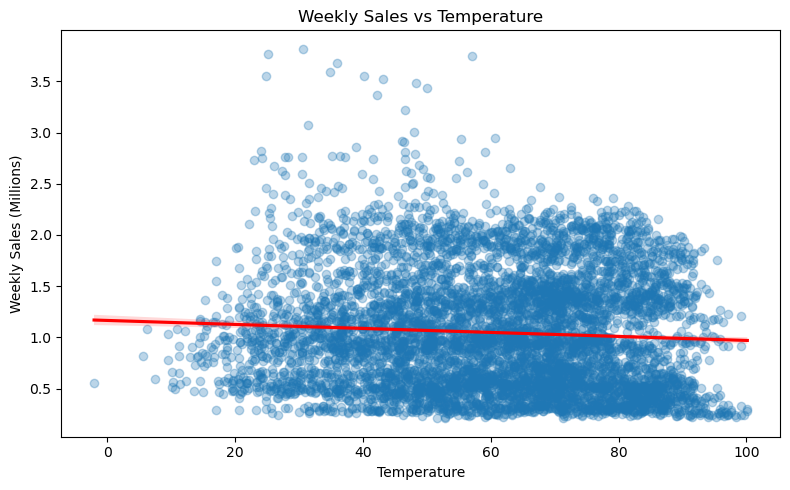

In [57]:
temperature_corr = df['Weekly_Sales(mn)'].corr(df['Temperature'])

print(f"Correlation between temperature and weekly sales: {temperature_corr:.3f}")

plt.figure(figsize=(8, 5))
sns.regplot(
    data=df,
    x='Temperature',
    y='Weekly_Sales(mn)',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title('Weekly Sales vs Temperature')
plt.xlabel('Temperature')
plt.ylabel('Weekly Sales (Millions)')
plt.tight_layout()
plt.show()

#### Observation:

- There has been seen a negative slope seen in regression plot for 'Temperature' & 'Weekly_Sales(mn)'

**d. How is the Consumer Price index affecting the weekly sales of various stores?**

In [59]:
df.head(5)

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekly_Sales(mn)
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,1.643691
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,1.641957
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,1.611968
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,1.409728
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,1.554807


In [60]:
correlation_list = []

for store_id, data in df.groupby('Store'):

    corr = data['Weekly_Sales(mn)'].corr(data['CPI'])

    correlation_list.append({
        'store_id': store_id,
        'correlation': corr
    })

corr_df = pd.DataFrame(correlation_list)


In [62]:
corr_df.sort_values(by ='correlation', ascending= True).head(10)

,store_id,correlation
35,36,-0.915095
34,35,-0.424107
13,14,-0.419755
29,30,-0.298188
42,43,-0.285686
26,27,-0.213082
17,18,-0.193541
14,15,-0.174467
20,21,-0.163649
18,19,-0.155341


**e. Top performing stores according to the historical data.**


In [65]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Weekly_Sales(mn)
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,1.643691
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,1.641957
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,1.611968
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,1.409728
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,1.554807


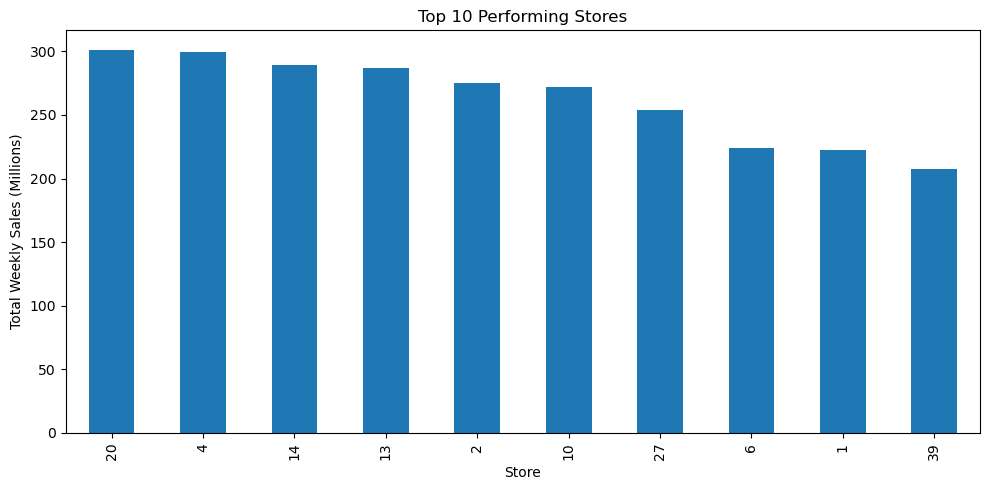

In [75]:
top_stores = df.groupby('Store').agg({'Weekly_Sales(mn)': 'sum'}).reset_index().sort_values(by='Weekly_Sales(mn)', ascending=False).head(10)


top_stores.plot(
    x='Store',
    y='Weekly_Sales(mn)',
    kind='bar',
    figsize=(10, 5),
    legend=False,
    title='Top 10 Performing Stores'
)

plt.xlabel('Store')
plt.ylabel('Total Weekly Sales (Millions)')
plt.tight_layout()
plt.show()

**f. The worst performing store, and how significant is the difference between the
highest and lowest performing stores.**

Worst-performing store: 33
Sales: $37.16 million
Best-performing store: 20
Sales: $301.40 million
Difference: $264.24 million
Percentage difference: 711.08%


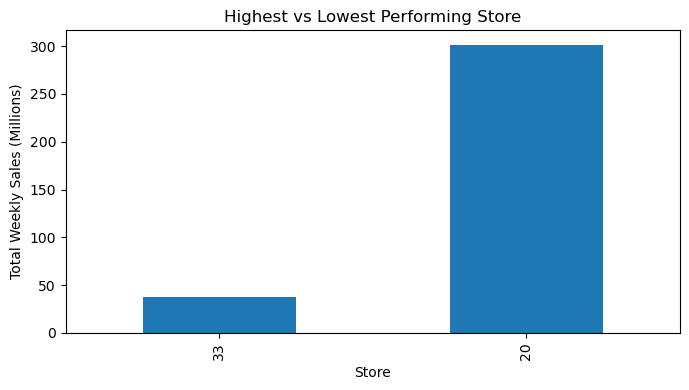

In [80]:
store_performance = (
    df.groupby('Store')['Weekly_Sales(mn)']
      .sum()
      .sort_values()
)

worst_store = store_performance.index[0]
best_store = store_performance.index[-1]
worst_sales = store_performance.iloc[0]
best_sales = store_performance.iloc[-1]

difference = best_sales - worst_sales
percentage_difference = (difference / worst_sales) * 100

print(f"Worst-performing store: {worst_store}")
print(f"Sales: ${worst_sales:.2f} million")
print(f"Best-performing store: {best_store}")
print(f"Sales: ${best_sales:.2f} million")
print(f"Difference: ${difference:.2f} million")
print(f"Percentage difference: {percentage_difference:.2f}%")

store_performance[[worst_store, best_store]].plot(
    kind='bar',
    figsize=(7, 4),
    title='Highest vs Lowest Performing Store',
    ylabel='Total Weekly Sales (Millions)',
    xlabel='Store',
    legend=False
)

plt.tight_layout()
plt.show()

### Model fitting

### Model Evaluation & validation

### Model Deployement